In [3]:
#Explorer les données
import pandas as pd
import json
from pathlib import Path

# Chemin vers le fichier
file_path = Path(r"C:\Users\SALMA\Desktop\tourisense-ai\data\raw\reviews\tripadvisor_tunisia_reviews.jl")

# Lecture du fichier (format JSON Lines)
data = []
with open(file_path, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            data.append(json.loads(line))

df = pd.DataFrame(data)

# Aperçu
print("="*60)
print(f"Nombre total d'avis : {len(df):,}")
print("="*60)
print("\nColonnes :")
print(df.columns.tolist())
print("\nTypes de données :")
print(df.dtypes)
print("\nAperçu des 5 premières lignes :")
print(df.head())
print("\nExemples de ratings :")
print(df["rating"].value_counts().head(10) if "rating" in df.columns else "Pas de colonne rating")

Nombre total d'avis : 111,587

Colonnes :
['hotel', 'address', 'rating', 'content', 'date']

Types de données :
hotel      str
address    str
rating     str
content    str
date       str
dtype: object

Aperçu des 5 premières lignes :
       hotel                      address rating  \
0  La_Badira  Hammamet_Nabeul_Governorate     50   
1  La_Badira  Hammamet_Nabeul_Governorate     50   
2  La_Badira  Hammamet_Nabeul_Governorate     40   
3  La_Badira  Hammamet_Nabeul_Governorate     50   
4  La_Badira  Hammamet_Nabeul_Governorate     50   

                                             content      date  
0  I had a recent stay at La Badira based on a fr...    Jan 17  
1  I was in this hotel for a week for my honeymoo...    Jan 10  
2  Very pleasant stay at la Badira  The room is s...  Dec 2020  
3  We are guests of La Badira since almost two ye...  Nov 2020  
4  I booked for the yoga weekend in full program,...  Oct 2020  

Exemples de ratings :
rating
50    52153
40    29654
30    146

In [4]:
#Nettoyage de base
import pandas as pd
import numpy as np
import re
from pathlib import Path

# --- 1. Conversion du rating ---
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

# Créer une note sur 5 (plus lisible)
df["rating_5"] = df["rating"] / 10

# Créer le label de sentiment simple
def rating_to_sentiment(r):
    if r >= 40:
        return "positif"
    elif r <= 20:
        return "négatif"
    else:
        return "neutre"

df["sentiment_label"] = df["rating"].apply(rating_to_sentiment)

# --- 2. Nettoyage basique du texte ---
def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    text = text.strip()
    text = re.sub(r'\s+', ' ', text)          # espaces multiples
    return text

df["content_clean"] = df["content"].apply(clean_text)

# Supprimer les avis vides
df = df[df["content_clean"].str.len() > 10].copy()

# --- 3. Extraire la région principale ---
df["region"] = df["address"].str.split("_").str[0]

# --- 4. Aperçu après nettoyage ---
print("="*60)
print(f"Nombre d'avis après nettoyage : {len(df):,}")
print("="*60)

print("\nRépartition des sentiments :")
print(df["sentiment_label"].value_counts())

print("\nTop 10 régions :")
print(df["region"].value_counts().head(10))

print("\nExemples de notes (rating_5) :")
print(df["rating_5"].value_counts().sort_index())

print("\nAperçu final :")
print(df[["hotel", "region", "rating_5", "sentiment_label", "content_clean"]].head(3))

Nombre d'avis après nettoyage : 111,587

Répartition des sentiments :
sentiment_label
positif    81807
négatif    15132
neutre     14648
Name: count, dtype: int64

Top 10 régions :
region
Hammamet    38451
Port        21034
Sousse      17178
Monastir    15391
Mahdia       3781
Tunis        3650
Midoun       3047
Gammarth     1240
La           1123
Djerba        992
Name: count, dtype: int64

Exemples de notes (rating_5) :
rating_5
1.0     8082
2.0     7050
3.0    14648
4.0    29654
5.0    52153
Name: count, dtype: int64

Aperçu final :
       hotel    region  rating_5 sentiment_label  \
0  La_Badira  Hammamet       5.0         positif   
1  La_Badira  Hammamet       5.0         positif   
2  La_Badira  Hammamet       4.0         positif   

                                       content_clean  
0  I had a recent stay at La Badira based on a fr...  
1  I was in this hotel for a week for my honeymoo...  
2  Very pleasant stay at la Badira The room is so...  


In [5]:
#Sauvegarder les données nettoyées
from pathlib import Path

# Créer le dossier s'il n'existe pas
output_dir = Path(r"C:\Users\SALMA\Desktop\tourisense-ai\data\processed\reviews")
output_dir.mkdir(parents=True, exist_ok=True)

# Sauvegarder en parquet (rapide et compact) + CSV (facile à relire)
df_clean = df[["hotel", "address", "region", "rating", "rating_5", 
               "sentiment_label", "content_clean", "date"]].copy()

# Parquet (recommandé)
df_clean.to_parquet(output_dir / "reviews_cleaned.parquet", index=False)

# CSV (backup)
df_clean.to_csv(output_dir / "reviews_cleaned.csv", index=False, encoding="utf-8")

print("Fichiers sauvegardés dans :")
print(output_dir)
print("\nFichiers créés :")
print(list(output_dir.glob("*")))

Fichiers sauvegardés dans :
C:\Users\SALMA\Desktop\tourisense-ai\data\processed\reviews

Fichiers créés :
[WindowsPath('C:/Users/SALMA/Desktop/tourisense-ai/data/processed/reviews/reviews_cleaned.csv'), WindowsPath('C:/Users/SALMA/Desktop/tourisense-ai/data/processed/reviews/reviews_cleaned.parquet'), WindowsPath('C:/Users/SALMA/Desktop/tourisense-ai/data/processed/reviews/reviews_sample_with_bert.csv'), WindowsPath('C:/Users/SALMA/Desktop/tourisense-ai/data/processed/reviews/reviews_sample_with_bert.parquet')]


In [6]:
#partie Sentiment Analysis
# installation À exécuter une seule fois
!pip install transformers torch sentencepiece accelerate -q

In [7]:

#Chargement des données + échantillon
import pandas as pd
from pathlib import Path

# Charger les données nettoyées
data_path = Path(r"C:\Users\SALMA\Desktop\tourisense-ai\data\processed\reviews\reviews_cleaned.parquet")
df = pd.read_parquet(data_path)

print(f"Total avis : {len(df):,}")

# Pour commencer, on travaille sur un échantillon (plus rapide)
# Tu pourras augmenter plus tard
df_sample = df.sample(n=3000, random_state=42).copy()
print(f"Échantillon utilisé : {len(df_sample):,}")

Total avis : 111,587
Échantillon utilisé : 3,000


In [8]:
#Pipeline de sentiment avec BERT
from transformers import pipeline
import torch

# Vérifier si GPU disponible
device = 0 if torch.cuda.is_available() else -1
print(f"Device utilisé : {'GPU' if device == 0 else 'CPU'}")

# Modèle multilingue (français + anglais + autres)
# Très bon pour des avis touristiques
sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    device=device,
    truncation=True,
    max_length=512
)

print("Modèle chargé avec succès.")

Device utilisé : CPU


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Modèle chargé avec succès.


In [9]:
#Prédiction sur l’échantillon
from tqdm.auto import tqdm

# Fonction pour prédire
def predict_sentiment(text):
    try:
        result = sentiment_pipeline(text)[0]
        return result["label"], result["score"]
    except Exception as e:
        return "ERROR", 0.0

# Appliquer (peut prendre quelques minutes selon ton PC)
tqdm.pandas()
df_sample[["bert_label", "bert_score"]] = df_sample["content_clean"].progress_apply(
    lambda x: pd.Series(predict_sentiment(x))
)

# Convertir le label BERT (1 star → 5 stars) en positif/neutre/négatif
def bert_to_sentiment(label):
    if label in ["4 stars", "5 stars"]:
        return "positif"
    elif label in ["1 star", "2 stars"]:
        return "négatif"
    else:
        return "neutre"

df_sample["bert_sentiment"] = df_sample["bert_label"].apply(bert_to_sentiment)

print("Prédictions terminées.")
print(df_sample[["rating_5", "sentiment_label", "bert_label", "bert_sentiment", "bert_score"]].head(10))

  0%|          | 0/3000 [00:00<?, ?it/s]

Prédictions terminées.
        rating_5 sentiment_label bert_label bert_sentiment  bert_score
100438       5.0         positif    5 stars        positif    0.864401
65356        5.0         positif    4 stars        positif    0.758205
80780        1.0         négatif     1 star        négatif    0.883970
19101        4.0         positif    5 stars        positif    0.606215
20629        1.0         négatif    3 stars         neutre    0.351507
90620        4.0         positif    3 stars         neutre    0.965450
81429        3.0          neutre    3 stars         neutre    0.438399
82960        5.0         positif    5 stars        positif    0.856988
11250        2.0         négatif    2 stars        négatif    0.478784
38213        4.0         positif    4 stars        positif    0.466228


In [10]:
#Évaluation rapide
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("Répartition BERT :")
print(df_sample["bert_sentiment"].value_counts())

print("\nRapport de classification (label note vs BERT) :")
print(classification_report(df_sample["sentiment_label"], df_sample["bert_sentiment"]))

Répartition BERT :
bert_sentiment
positif    1969
négatif     640
neutre      391
Name: count, dtype: int64

Rapport de classification (label note vs BERT) :
              precision    recall  f1-score   support

      neutre       0.32      0.35      0.33       362
     négatif       0.53      0.80      0.64       423
     positif       0.94      0.83      0.88      2215

    accuracy                           0.77      3000
   macro avg       0.60      0.66      0.62      3000
weighted avg       0.80      0.77      0.78      3000



In [11]:
from pathlib import Path

output_dir = Path(r"C:\Users\SALMA\Desktop\tourisense-ai\data\processed\reviews")

# Sauvegarder l'échantillon avec les prédictions BERT
df_sample.to_parquet(output_dir / "reviews_sample_with_bert.parquet", index=False)
df_sample.to_csv(output_dir / "reviews_sample_with_bert.csv", index=False, encoding="utf-8")

print("Résultats BERT sauvegardés.")
print(df_sample.columns.tolist())

Résultats BERT sauvegardés.
['hotel', 'address', 'region', 'rating', 'rating_5', 'sentiment_label', 'content_clean', 'date', 'bert_label', 'bert_score', 'bert_sentiment']


In [12]:
#BERTopic (détection des tendances / thèmes) sur les 3000 avis.
#Installation
!pip install bertopic -q

In [13]:
#Préparation des données pour BERTopic
import pandas as pd
from pathlib import Path

# Charger l'échantillon avec les prédictions BERT (ou les données nettoyées)
data_path = Path(r"C:\Users\SALMA\Desktop\tourisense-ai\data\processed\reviews\reviews_sample_with_bert.parquet")

# Si le fichier n'existe pas encore, recharge les données nettoyées + prends un échantillon
if not data_path.exists():
    df = pd.read_parquet(r"C:\Users\SALMA\Desktop\tourisense-ai\data\processed\reviews\reviews_cleaned.parquet")
    df_sample = df.sample(n=3000, random_state=42).copy()
else:
    df_sample = pd.read_parquet(data_path)

# On garde uniquement les textes non vides
docs = df_sample["content_clean"].dropna().tolist()
print(f"Nombre de documents pour BERTopic : {len(docs)}")

Nombre de documents pour BERTopic : 3000


In [14]:
!python -m pip install --upgrade pip

In [15]:
!pip install nltk

In [16]:
#entraînement BERTopic
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
import nltk
from nltk.corpus import stopwords

# Stopwords
nltk.download('stopwords', quiet=True)
stop_words = list(stopwords.words('english')) + list(stopwords.words('french'))

# Vectorizer simple et robuste
vectorizer_model = CountVectorizer(
    stop_words=stop_words,
    ngram_range=(1, 2)
)

embedding_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

topic_model = BERTopic(
    embedding_model=embedding_model,
    vectorizer_model=vectorizer_model,
    language="multilingual",
    min_topic_size=40,          # un peu plus élevé pour des topics plus stables
    nr_topics="auto",           # laisse BERTopic réduire automatiquement
    calculate_probabilities=True,
    verbose=True
)

# Entraînement
topics, probs = topic_model.fit_transform(docs)

print("Modèle entraîné avec succès.")
print(f"Nombre de topics trouvés : {len(set(topics)) - 1}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

2026-08-06 17:46:50,488 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/94 [00:00<?, ?it/s]

2026-08-06 17:53:09,983 - BERTopic - Embedding - Completed ✓
2026-08-06 17:53:09,986 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-08-06 17:55:20,420 - BERTopic - Dimensionality - Completed ✓
2026-08-06 17:55:20,423 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-08-06 17:55:20,978 - BERTopic - Cluster - Completed ✓
2026-08-06 17:55:20,980 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-08-06 17:55:23,621 - BERTopic - Representation - Completed ✓
2026-08-06 17:55:23,627 - BERTopic - Topic reduction - Reducing number of topics
2026-08-06 17:55:23,662 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-08-06 17:55:26,237 - BERTopic - Representation - Completed ✓
2026-08-06 17:55:26,244 - BERTopic - Topic reduction - Reduced number of topics from 2 to 2


Modèle entraîné avec succès.
Nombre de topics trouvés : 1


In [17]:
#Voir les topics principaux
# Afficher les 15 premiers topics
topic_info = topic_model.get_topic_info()
print(topic_info.head(15))

print("\n--- Mots-clés des topics ---")
for i in range(min(10, len(set(topics))-1)):
    print(f"\nTopic {i}:")
    print(topic_model.get_topic(i)[:10])

   Topic  Count                       Name  \
0      0   2410    0_hotel_staff_room_food   
1      1    590  1_hotel_tunisia_food_good   

                                      Representation  \
0  [hotel, staff, room, food, good, great, clean,...   
1  [hotel, tunisia, food, good, staff, room, time...   

                                 Representative_Docs  
0  [My wife and i stayed at this Hotel in May 201...  
1  [2nd time to Tunisia 1st time to this hotel, a...  

--- Mots-clés des topics ---

Topic 0:
[('hotel', np.float64(0.048316187606843405)), ('staff', np.float64(0.029609055308790964)), ('room', np.float64(0.027790503455624387)), ('food', np.float64(0.026766403982883533)), ('good', np.float64(0.02520055590519448)), ('great', np.float64(0.01868155987969357)), ('clean', np.float64(0.0185470998539327)), ('pool', np.float64(0.017708828222636197)), ('rooms', np.float64(0.01725543076924244)), ('holiday', np.float64(0.017230583984366794))]


In [18]:
# Réduction manuelle + forcer plus de topics
topic_model = BERTopic(
    embedding_model=embedding_model,
    vectorizer_model=vectorizer_model,
    language="multilingual",
    min_topic_size=20,          # plus bas = plus de topics
    nr_topics=12,               # on force environ 12 topics
    calculate_probabilities=True,
    verbose=True
)

topics, probs = topic_model.fit_transform(docs)

print(f"Nombre de topics trouvés : {len(set(topics)) - 1}")

# Affichage
topic_info = topic_model.get_topic_info()
print(topic_info.head(15))

print("\n--- Mots-clés des topics ---")
for i in range(min(12, len(set(topics))-1)):
    print(f"\nTopic {i}:")
    print(topic_model.get_topic(i)[:10])

2026-08-06 17:55:26,717 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/94 [00:00<?, ?it/s]

2026-08-06 18:02:23,844 - BERTopic - Embedding - Completed ✓
2026-08-06 18:02:23,847 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-08-06 18:03:16,973 - BERTopic - Dimensionality - Completed ✓
2026-08-06 18:03:16,977 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-08-06 18:03:17,702 - BERTopic - Cluster - Completed ✓
2026-08-06 18:03:17,706 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-08-06 18:03:21,268 - BERTopic - Representation - Completed ✓
2026-08-06 18:03:21,274 - BERTopic - Topic reduction - Reducing number of topics
2026-08-06 18:03:21,275 - BERTopic - Topic reduction - Number of topics (12) is equal or higher than the clustered topics(4).
2026-08-06 18:03:21,276 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-08-06 18:03:25,277 - BERTopic - Representation - Completed ✓


Nombre de topics trouvés : 3
   Topic  Count                               Name  \
0     -1     11         -1_hotel_beach_palace_food   
1      0   2412            0_hotel_staff_room_food   
2      1     37  1_sahara_hotel_sahara beach_beach   
3      2    540         2_hotel_tunisia_good_staff   

                                      Representation  \
0  [hotel, beach, palace, food, great, inclusive,...   
1  [hotel, staff, room, food, good, great, clean,...   
2  [sahara, hotel, sahara beach, beach, food, hol...   
3  [hotel, tunisia, good, staff, food, room, time...   

                                 Representative_Docs  
0  [Back less than a week from the El Hana Palace...  
1  [The hotel is great, the location amazing, the...  
2  [We (3 adults) stayed at the Sahara Beach from...  
3  [2nd time to Tunisia 1st time to this hotel, a...  

--- Mots-clés des topics ---

Topic 0:
[('hotel', np.float64(0.03953177944751564)), ('staff', np.float64(0.024962079905970394)), ('room', np.fl

In [23]:
#Visualisations (optionnel mais utile)
# Visualisation interactive des topics
#fig = topic_model.visualize_topics()
#fig.show()

# Visualisation de la hiérarchie des topics
#fig2 = topic_model.visualize_hierarchy()
#fig2.show()

In [24]:
#Sauvegarder les résultats BERTopic
from pathlib import Path

output_dir = Path(r"C:\Users\SALMA\Desktop\tourisense-ai\data\processed\reviews")
output_dir.mkdir(parents=True, exist_ok=True)

# Ajouter les topics à l'échantillon
df_sample = df_sample.copy()
df_sample["topic"] = topics

# Sauvegarder
df_sample.to_parquet(output_dir / "reviews_with_topics.parquet", index=False)
df_sample.to_csv(output_dir / "reviews_with_topics.csv", index=False, encoding="utf-8")

# Sauvegarder aussi les infos des topics
topic_info.to_csv(output_dir / "bertopic_topics_info.csv", index=False)

print("Résultats BERTopic sauvegardés.")
print(f"Fichiers créés dans : {output_dir}")
print(df_sample["topic"].value_counts())

Résultats BERTopic sauvegardés.
Fichiers créés dans : C:\Users\SALMA\Desktop\tourisense-ai\data\processed\reviews
topic
 0    2412
 2     540
 1      37
-1      11
Name: count, dtype: int64


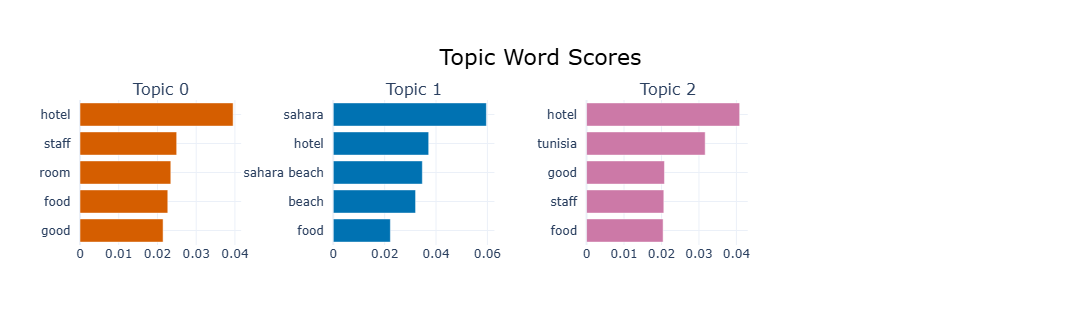

In [22]:
# Visualisation simple : Bar chart des topics (fonctionne même avec peu de topics)
fig = topic_model.visualize_barchart(top_n_topics=5)
fig.show()